# Which Penguin? — Species Classification with a Production-Style Pipeline

Predict whether a penguin is an **Adelie**, **Chinstrap** or **Gentoo** from its bill, flipper and body measurements, island and sex, using the [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) dataset.

The goal is not just accuracy but a **single deployable artifact**: a scikit-learn `Pipeline` that takes *raw* rows (including missing values and unseen categories) and returns a prediction.

**Outline**
1. Load & explore the data
2. Train/test split
3. Build the preprocessing + model pipeline
4. Tune and compare four models with cross-validation
5. Evaluate the best model on the held-out test set
6. Interpret the model
7. Save the model

In [ ]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
from sklearn import set_config
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, recall_score

from which_penguin.pipeline import (
    MODELS, NUMERIC_FEATURES,
    build_pipeline, compare_models, load_data, split_data,
)

set_config(transform_output="pandas", display="diagram")
sns.set_theme(style="ticks", font_scale=0.8, rc={"figure.figsize": (6, 4)})

FIGURES = Path("../reports/figures")
MODEL_DIR = Path("../models")
FIGURES.mkdir(parents=True, exist_ok=True)

## 1. Load & explore the data

In [2]:
data = load_data()
print(f"Data shape: {data.shape}")
data.head()

Data shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


Missing values per column. A few rows lack measurements and several lack `sex` — the pipeline will impute these rather than dropping rows, so the deployed model can also cope with incomplete input.

In [3]:
data.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [4]:
data["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Classes are imbalanced (Chinstrap is the smallest), so the train/test split is **stratified** by species.

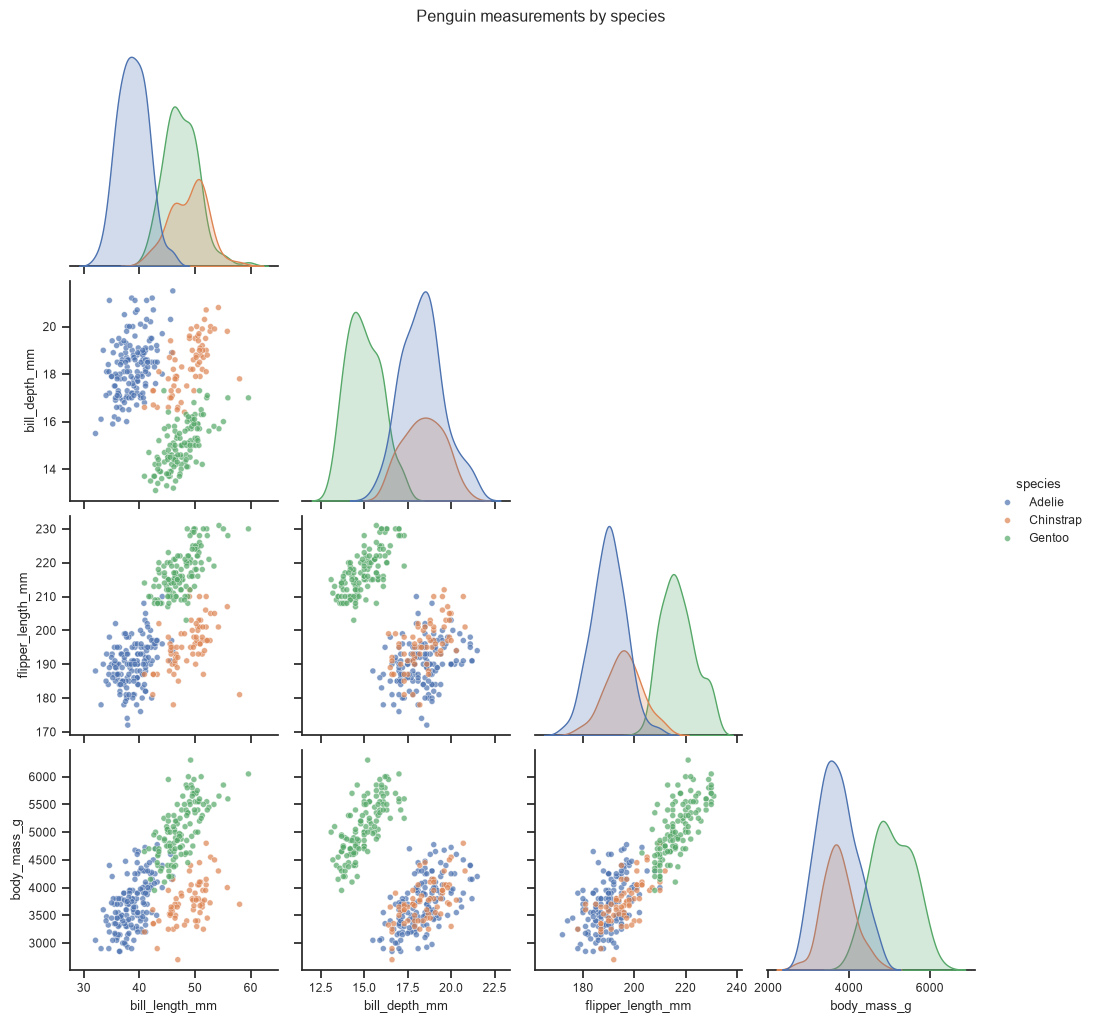

In [5]:
g = sns.pairplot(data, hue="species", vars=NUMERIC_FEATURES, corner=True,
                 plot_kws={"alpha": 0.7, "s": 18})
g.figure.suptitle("Penguin measurements by species", y=1.02)
g.savefig(FIGURES / "pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

Gentoo separates cleanly on flipper length and body mass; Adelie vs. Chinstrap is mainly distinguished by **bill length**. A linear model should do well here.

## 2. Train/test split

The test set is held out until the very end — all model selection happens via cross-validation on the training set.

In [6]:
X_train, X_test, y_train, y_test = split_data(data)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (275, 6), Test: (69, 6)


## 3. Build the pipeline

`build_pipeline()` (in `src/which_penguin/pipeline.py`) chains:

| Step | Numeric features | Categorical features |
|---|---|---|
| Impute | median | most frequent |
| Transform | `StandardScaler` | `OneHotEncoder(handle_unknown="ignore")` |
| Model | any classifier (compared in section 4) | |

Because imputation and scaling are fitted *inside* the pipeline, cross-validation never leaks test-fold statistics into training.

In [7]:
classifier, _ = MODELS["Logistic regression"]
pipeline = build_pipeline(classifier)
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature

## 4. Tune and compare models with cross-validation

Four model families, each tuned with a grid search and 5-fold cross-validation on the training set:

| Model | How it decides |
|---|---|
| Logistic regression | weighted sum of features → straight-line boundaries |
| K-nearest neighbours | majority species among the closest training penguins |
| Decision tree | a learned sequence of if/else questions |
| Random forest | many decision trees on random subsets, voting together |

Each model is scored on **accuracy** and **macro recall** (recall averaged equally over the three species, so the small Chinstrap class counts as much as the others). The best settings for each model are chosen by CV accuracy.

In [8]:
# The hyperparameters searched for each model
{name: grid for name, (_, grid) in MODELS.items()}

{'Logistic regression': {'C': [0.01, 0.1, 1, 10, 100], 'l1_ratio': [0.0, 1.0]},
 'K-nearest neighbours': {'n_neighbors': [1, 3, 5, 7, 9, 15],
  'weights': ['uniform', 'distance']},
 'Decision tree': {'max_depth': [2, 3, 4, 5, None],
  'min_samples_leaf': [1, 5, 10]},
 'Random forest': {'n_estimators': [100, 300], 'max_depth': [3, 5, None]}}

In [20]:
results, searches = compare_models(X_train, y_train, X_test, y_test)
results.round(4)

,cv_accuracy,cv_recall,test_accuracy,test_recall,best_params
model,,,,,
Logistic regression,0.9964,0.9967,0.9855,0.9889,"{'C': 10, 'l1_ratio': 0.0}"
K-nearest neighbours,0.9927,0.9939,0.9855,0.9889,"{'n_neighbors': 1, 'weights': 'uniform'}"
Random forest,0.9855,0.9818,1.0000,1.0000,"{'max_depth': None, 'n_estimators': 100}"
Decision tree,0.9564,0.9521,0.9855,0.9889,"{'max_depth': 4, 'min_samples_leaf': 1}"


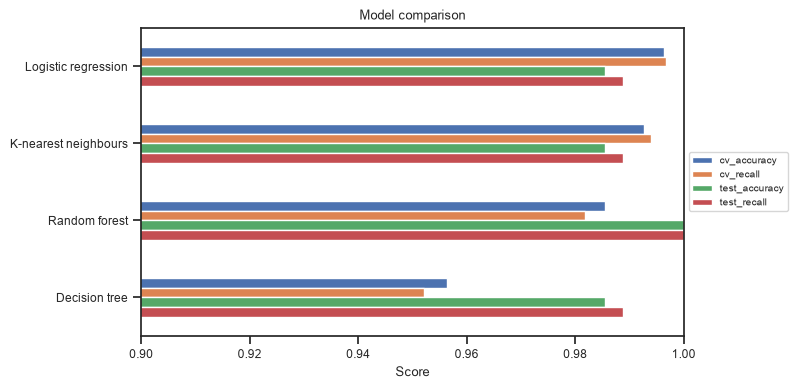

In [10]:
ax = results[["cv_accuracy", "cv_recall", "test_accuracy", "test_recall"]].plot.barh(figsize=(7, 4))
ax.set_xlim(0.9, 1.0)
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=7)
ax.set_title("Model comparison")
ax.figure.savefig(FIGURES / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

**Reading the results**

- **Logistic regression** has the best CV accuracy, with **K-nearest neighbours** just behind. KNN's best setting is `k=1` (copy the single closest penguin), which works here because the species form tight clusters, but it would be sensitive to noisy data.
- **Random forest** scores 100% on the test set but lower in cross-validation. Picking it because of the test score would be cherry-picking a lucky split of 69 penguins, so the **test score is reported for reference only and never used to choose**.
- **A single decision tree** is the weakest. Its splits are one feature at a time, which suits a clean threshold (e.g. flipper length for Gentoo) but approximates the Adelie/Chinstrap boundary less smoothly. The random forest averages many trees, which fixes much of that.
- Each CV fold holds about 55 penguins, so one misclassified penguin moves a fold's accuracy by almost 2 points. The top three models are within noise of each other, so the simplest and most interpretable one, logistic regression, is a sensible choice.

In [11]:
best_name = results.index[0]  # highest CV accuracy
model = searches[best_name].best_estimator_

print(f"Best model:           {best_name}")
print(f"Best params:          {results.loc[best_name, 'best_params']}")
print(f"CV Train accuracy:    {results.loc[best_name, 'cv_accuracy']:.4f}")

Best model:           Logistic regression
Best params:          {'C': 10, 'l1_ratio': 0.0}
CV Train accuracy:    0.9964


## 5. Evaluate on the held-out test set

In [12]:
y_pred = model.predict(X_test)
print(f"Test accuracy: {model.score(X_test, y_test):.4f}\n")
print(classification_report(y_test, y_pred))

Test accuracy: 0.9855

              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



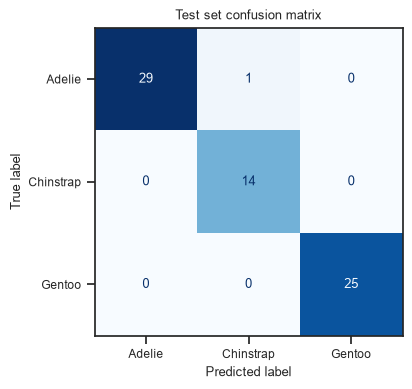

In [13]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Test set confusion matrix")
fig.savefig(FIGURES / "confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

With only 69 test penguins, a single misclassification moves accuracy by ~1.4 points, so the CV score is the more reliable estimate of generalisation.

### Comparing all four models on the test set

The scores above are single numbers. The confusion matrices show *which* species each model confuses, and the recall table shows how well each model finds every species.

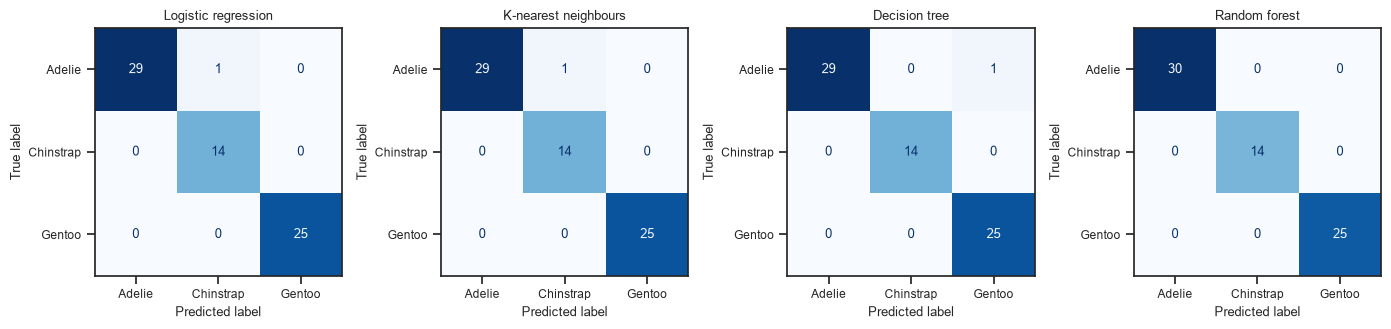

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

for ax, (name, search) in zip(axes, searches.items()):
    ConfusionMatrixDisplay.from_estimator(search, X_test, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

fig.tight_layout()
fig.savefig(FIGURES / "confusion_matrices_all_models.png", dpi=120, bbox_inches="tight")
plt.show()

In [15]:
species = sorted(y_test.unique())

recall_by_species = pd.DataFrame({
    name: recall_score(y_test, search.predict(X_test), labels=species, average=None)
    for name, search in searches.items()
}, index=species).T

recall_by_species.round(3)

,Adelie,Chinstrap,Gentoo
Logistic regression,0.967,1.0,1.0
K-nearest neighbours,0.967,1.0,1.0
Decision tree,0.967,1.0,1.0
Random forest,1.000,1.0,1.0


**What the comparison shows**

- Every model finds **all Chinstrap and Gentoo penguins**. The only errors are single Adelie penguins, so no model neglects the small Chinstrap class.
- **Logistic regression and KNN miss the same penguin**: an Adelie on Dream island with a 42.2 mm bill, longer than the Adelie average (38.8 mm). Long bills and Dream island are both typical of Chinstraps, so this penguin is genuinely ambiguous.
- **The decision tree misses a different Adelie**, one with a 210 mm flipper, close to the Gentoo average (217 mm). A single tree splits on one feature at a time, so one Gentoo-like measurement can send a penguin down the wrong branch even though its deep bill (18.0 mm) is clearly not Gentoo-like.
- **The random forest gets all 69 right.** Averaging many trees smooths out the single tree's hard thresholds. Its CV accuracy is still lower than logistic regression's, though, so this is one lucky test split, not evidence that it is the better model.

The differences between models come down to one or two penguins, which confirms the conclusion from cross-validation: on this dataset, the simple linear model is as good as anything else.

## 6. Interpret the model

The best model is logistic regression, so its coefficients can be read directly. Coefficients are on standardised features, so their magnitudes are comparable. Positive values push towards that species.

In [16]:
clf = model.named_steps["classifier"]
preprocessor = model.named_steps["preprocessor"]

print(f"Classifier: {clf}")
print(f"Preprocessor: {preprocessor}")

feature_names = preprocessor.get_feature_names_out()
coef_df = pd.DataFrame(clf.coef_.T, index=feature_names, columns=clf.classes_)
coef_df

Classifier: LogisticRegression(C=10, max_iter=5000, random_state=42, solver='saga')
Preprocessor: ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['bill_length_mm', 'bill_depth_mm',
                                  'flipper_length_mm', 'body_mass_g']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['island', 'sex'])],
         

,Adelie,Chinstrap,Gentoo
bill_length_mm,-4.411328,3.375643,1.035685
bill_depth_mm,1.887677,0.254113,-2.141790
flipper_length_mm,-0.502792,-0.519437,1.022229
body_mass_g,0.378731,-1.136222,0.757491
island_Biscoe,-0.428323,-1.225846,1.654170
island_Dream,-0.758432,1.806719,-1.048287
island_Torgersen,1.362113,-0.738493,-0.623620
sex_Female,-0.584716,0.921299,-0.336583
sex_Male,0.760074,-1.078920,0.318846


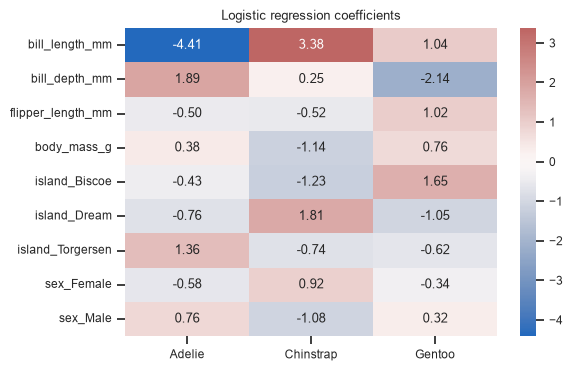

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(coef_df, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Logistic regression coefficients")
fig.savefig(FIGURES / "coefficients.png", dpi=120, bbox_inches="tight")
plt.show()

Bill length is the strongest signal for Adelie (negative) vs. Chinstrap (positive); bill depth separates Gentoo (shallow bills) from the others.

## 7. Save & reload the model

The whole pipeline is a single file, so inference code only needs raw feature values.

In [18]:
MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "penguin_classifier.joblib"
joblib.dump(model, model_path)

reloaded = joblib.load(model_path)
sample = X_test.iloc[[0]].copy()
sample["predicted_species"] = reloaded.predict(sample)
sample["actual_species"] = y_test.iloc[0]
sample

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island,sex,predicted_species,actual_species
151,41.5,18.5,201.0,4000.0,Dream,Male,Adelie,Adelie
